# DimExDAM: обучение и инференс на керне из `data/`

Реализация статьи *Generating Heterogeneous 3D Geological Microstructures from 2D Images via a Stable Diffusion-Adversarial Model* (Aouf et al.).

Авторы не опубликовали веса, а модель безусловная (одна модель на один материал), поэтому сначала **обучаем** её на керне, затем делаем **инференс**.

**Схема:**
1. Из 3D-керна берём **только 3 ортогональных среза** (XY, XZ, YZ). Остальной объём модель не видит, он нужен только как ground truth для проверки.
2. 3D-генератор `G(x_{t+1}, t, z) → x̂₀` за **T = 8 шагов** диффузии превращает шум в объём.
3. Один 2D-дискриминатор сравнивает срезы сгенерированного объёма с реальными срезами на каждом шаге t.
4. Инференс: шум → 8 проходов G → бинаризация.

Код модели лежит в `src/dimexdam/` (`models.py`, `diffusion.py`, `train.py`).

In [1]:
from pathlib import Path
import numpy as np, torch, matplotlib.pyplot as plt
from dimexdam.data import load_mhd, ortho_slices
from dimexdam.train import Trainer, Config, load_generator
from dimexdam.diffusion import Diffusion
from dimexdam import metrics

VARIANT  = "Variant_01"   # какой керн из data/
N_ITERS  = 3000           # итераций обучения (~1 с каждая на RTX 5060 Ti)
RETRAIN  = False          # True: обучить заново, даже если чекпойнт уже есть
DEVICE   = "cuda"
ROOT     = Path("..")
CKPT     = ROOT / "checkpoints" / f"{VARIANT}.pt"
CKPT.parent.mkdir(exist_ok=True)
torch.manual_seed(0); np.random.seed(0)

C:\Users\Admin\Desktop\DCP_project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Данные
Керн 300³, бинарный {0, 1}. Для обучения берём только центральные срезы по трём осям.

(300, 300, 300) | доля фазы 0: 0.429, фазы 1: 0.571


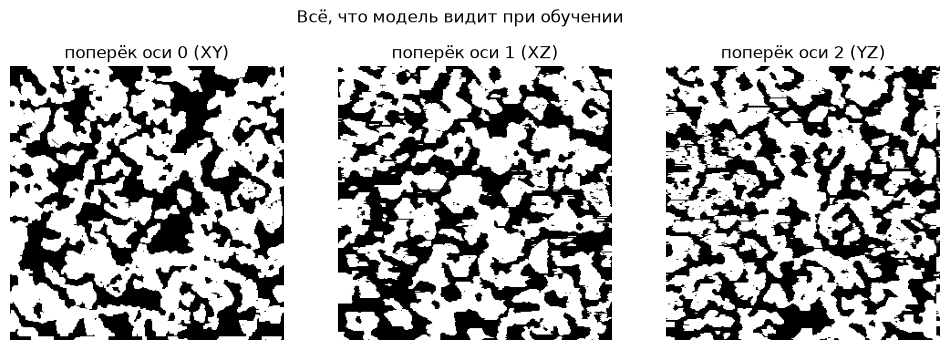

In [2]:
vol = load_mhd(ROOT / "data" / VARIANT / "model.mhd")
print(vol.shape, "| доля фазы 0: %.3f, фазы 1: %.3f" % ((vol == 0).mean(), (vol == 1).mean()))

train_slices = ortho_slices(vol)          # 3 картинки 300×300 в диапазоне [-1, 1]
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, s, name in zip(ax, train_slices, ["поперёк оси 0 (XY)", "поперёк оси 1 (XZ)", "поперёк оси 2 (YZ)"]):
    a.imshow(s, cmap="gray"); a.set_title(name); a.axis("off")
plt.suptitle("Всё, что модель видит при обучении"); plt.show()

## 2. Обучение
Если чекпойнт уже есть, обучение пропускается. Low-pass curriculum (размытие реальных срезов) действует первые 7 «эпох» по 100 итераций.

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:01<?, ?it/s, D=1.493, G=0.692, epoch=0]

  0%|          | 1/3000 [00:01<1:31:17,  1.83s/it, D=1.493, G=0.692, epoch=0]

  0%|          | 1/3000 [00:02<1:31:17,  1.83s/it, D=1.408, G=0.770, epoch=0]

  0%|          | 2/3000 [00:02<1:06:11,  1.32s/it, D=1.408, G=0.770, epoch=0]

...

100%|█████████▉| 2998/3000 [47:09<00:01,  1.07it/s, D=0.820, G=1.165, epoch=29]

100%|█████████▉| 2999/3000 [47:09<00:00,  1.07it/s, D=0.820, G=1.165, epoch=29]

100%|█████████▉| 2999/3000 [47:10<00:00,  1.07it/s, D=0.869, G=1.146, epoch=30]

100%|██████████| 3000/3000 [47:10<00:00,  1.03it/s, D=0.869, G=1.146, epoch=30]

100%|██████████| 3000/3000 [47:10<00:00,  1.06it/s, D=0.869, G=1.146, epoch=30]

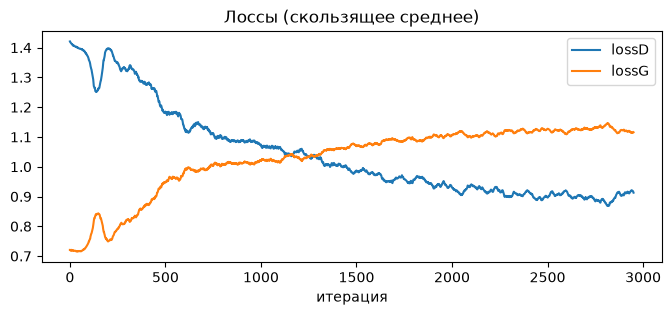

In [3]:
trainer = Trainer(train_slices, Config(), DEVICE)
if CKPT.exists() and not RETRAIN:
    trainer.load(CKPT); print(f"Загружен чекпойнт: {trainer.step} итераций")
else:
    trainer.fit(N_ITERS, ckpt=CKPT)

# Кривые лоссов. Если D уходит в 0, а G растёт, обучение схлопнулось (рис. 7 статьи).
smooth = lambda v, k=50: np.convolve(v, np.ones(min(k, len(v))) / min(k, len(v)), mode="valid")
plt.figure(figsize=(8, 3))
for k, v in trainer.hist.items(): plt.plot(smooth(v), label=k)
plt.xlabel("итерация"); plt.legend(); plt.title("Лоссы (скользящее среднее)"); plt.show()

## 3. Инференс
Для генерации нужен только генератор: шум $x_T$, затем 8 шагов $\hat x_0 = G(x_{t+1}, t, z)$, $x_t \sim q(x_t \mid x_{t+1}, \hat x_0)$. После этого бинаризуем по порогу 0.

In [4]:
G, cfg = load_generator(CKPT, DEVICE)
diff = Diffusion(cfg.T, DEVICE)

N_GEN, SIZE = 16, cfg.size               # SIZE можно увеличить (кратно 8): сеть полностью свёрточная
gen = torch.cat([diff.sample(G, 4, SIZE, cfg.nz, DEVICE) for _ in range(N_GEN // 4)])
gen_raw = gen[:, 0].cpu().numpy()                     # «сырой» выход в [-1, 1]
gen_bin = (gen_raw > 0).astype(np.uint8)              # бинарный объём {0, 1}
real_sub = metrics.random_subvolumes(vol, N_GEN, SIZE)   # эталонные кубы из ground truth
print("сгенерировано:", gen_bin.shape)

сгенерировано: (16, 64, 64, 64)


## 4. Визуальное сравнение
Срезы по трём плоскостям: ground truth (случайный куб из керна), сырой выход и бинаризованный выход модели.

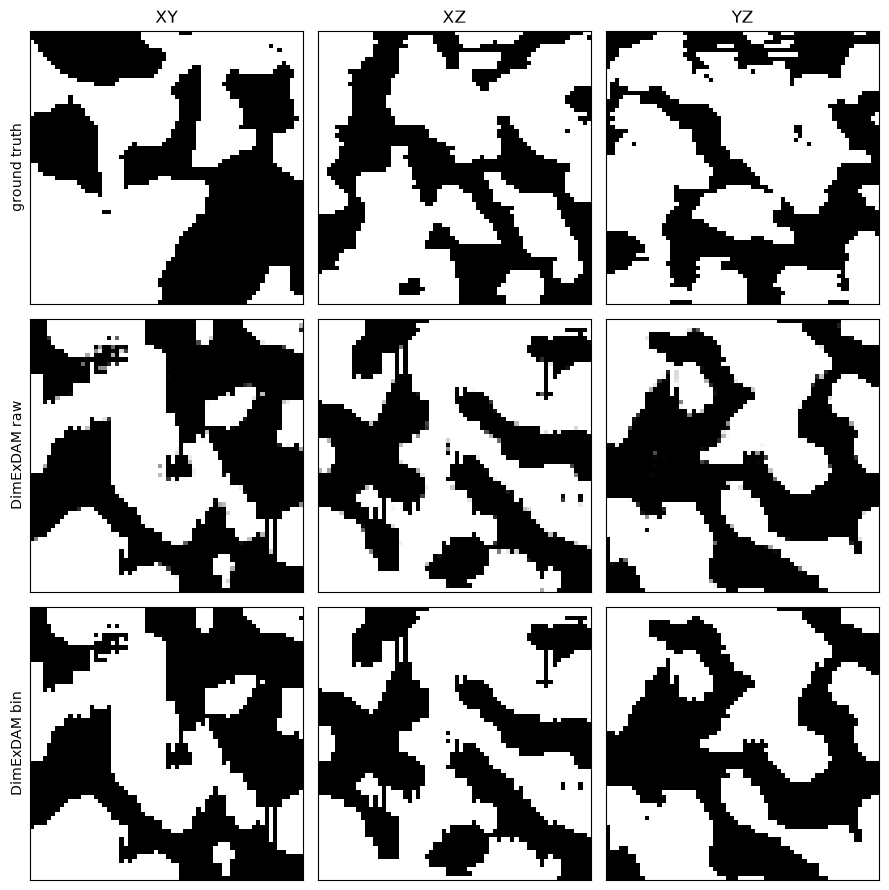

In [5]:
def mid(v, axis): return np.take(v, v.shape[axis] // 2, axis=axis)

rows = [("ground truth", real_sub[0]), ("DimExDAM raw", gen_raw[0]), ("DimExDAM bin", gen_bin[0])]
fig, ax = plt.subplots(3, 3, figsize=(9, 9))
for i, (name, v) in enumerate(rows):
    for p in range(3):
        ax[i, p].imshow(mid(v, p), cmap="gray"); ax[i, p].set_xticks([]); ax[i, p].set_yticks([])
    ax[i, 0].set_ylabel(name)
for p, n in enumerate(["XY", "XZ", "YZ"]): ax[0, p].set_title(n)
plt.tight_layout(); plt.show()

## 5. Количественное сравнение
- **Доля фазы 0** (пористость, если поры кодируются нулём) по сгенерированным объёмам и по кубам того же размера из ground truth.
- **Двухточечная функция S₂(r)** по трём осям.

доля фазы 0  GT: 0.416 ± 0.027 | GEN: 0.421 ± 0.002 | весь керн: 0.429


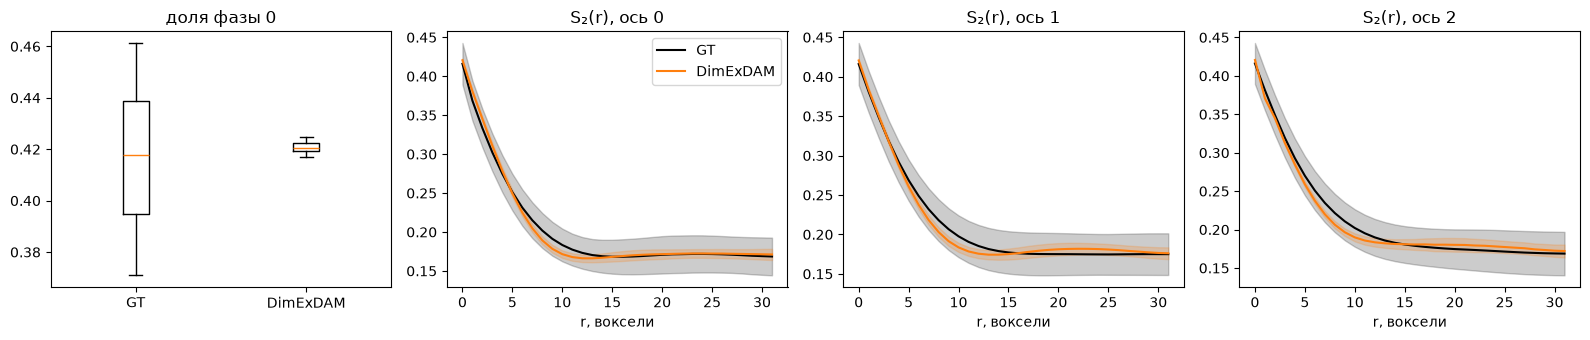

In [6]:
pf_real = [metrics.phase_fraction(v) for v in real_sub]
pf_gen  = [metrics.phase_fraction(v) for v in gen_bin]
print("доля фазы 0  GT: %.3f ± %.3f | GEN: %.3f ± %.3f | весь керн: %.3f"
      % (np.mean(pf_real), np.std(pf_real), np.mean(pf_gen), np.std(pf_gen), metrics.phase_fraction(vol)))

fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
ax[0].boxplot([pf_real, pf_gen]); ax[0].set_xticks([1, 2], ["GT", "DimExDAM"]); ax[0].set_title("доля фазы 0")
for p in range(3):
    for vols, c, lab in [(real_sub, "k", "GT"), (gen_bin, "C1", "DimExDAM")]:
        s = np.array([metrics.s2(v, p) for v in vols])
        ax[p + 1].plot(s.mean(0), c, label=lab)
        ax[p + 1].fill_between(range(s.shape[1]), s.mean(0) - s.std(0), s.mean(0) + s.std(0), color=c, alpha=.2)
    ax[p + 1].set_title(f"S₂(r), ось {p}"); ax[p + 1].set_xlabel("r, воксели")
ax[1].legend(); plt.tight_layout(); plt.show()

## 6. Сохранение
Сгенерированные объёмы сохраняются в `.npy`. Дальше их можно анализировать в PoreSpy или считать на них проницаемость и диффузию.

In [7]:
out = ROOT / "outputs" / VARIANT; out.mkdir(parents=True, exist_ok=True)
np.save(out / "generated.npy", gen_bin)
print("сохранено:", out / "generated.npy", gen_bin.shape)

сохранено: ..\outputs\Variant_01\generated.npy (16, 64, 64, 64)
